# E-Commerce Customer Cohort, Retention & Profitability Analysis

**Author:** Pham Hong Hieu (Haven) · [Portfolio](https://haven-portfolio02.vercel.app) · [GitHub](https://github.com/Haven-Pham)

## Business context
A global e-commerce retailer (synthetic educational dataset) grew sales every year from 2020 to 2023. Management wants to know
whether that growth is built on **customers who come back** and whether it is **profitable**.

## Business questions
1. How many new customers come back, and when?
2. Do retention patterns differ by cohort and by customer segment?
3. How much of the profit comes from repeat customers?
4. Which customer groups and pricing practices drive or destroy profit?
5. What should the business do next?

## Executive summary
- **Growth without profit in 2023:** sales rose **+24%** to $2.19M but profit fell **−12%**; the margin dropped from **18.0% to 12.8%** in every product category and every discount band, which points to a company-wide price or cost change rather than discounting or product mix.
- **Retention is the profit engine:** only **31%** of customers ever buy twice, yet they deliver **56% of profit** and earn **$110.6** each vs **$38.8** for one-time buyers (2.9×).
- **Customers return slowly:** only **1.6%–2.4%** of a cohort buys again in any later month and the median gap to the 2nd purchase is **364 days**; only 14.5% return within 90 days.
- **Deep discounts destroy value:** order lines with discounts above 20% (22% of lines) lost **$289K** over four years.
- **Income is not a useful targeting variable:** each income bracket's share of profit matches its share of customers (profit per customer $54–62).

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Works whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from cohort_analysis import (
    DISCOUNT_BINS, DISCOUNT_LABELS, add_cohort_columns, cohort_counts, discount_profitability,
    income_profitability, load_customers, load_products, load_sales, margin_by_year, pooled_retention, purchase_events,
    repeat_purchase_summary, retention_matrix, segment_summary, time_to_second_purchase, validate, yearly_kpis,
)
from cohort_analysis.plots import BLUE, GREEN, GREY, NAVY, RED, SKY, percent_axis, save, set_style

DATA_DIR = ROOT / "data" / "raw"
FIGURES = ROOT / "reports" / "figures"
TABLES = ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
print(f"pandas {pd.__version__} · seaborn {sns.__version__}")

pandas 2.2.3 · seaborn 0.13.2


## 2. Load and validate the data
Two tables are used: `EcomSales` (one row per order line) and `Customer` (ID and annual income only; names, e-mails and
birth dates were removed from the published copy because the analysis does not need them).
Blocking checks (duplicate keys, missing values, orphan customers) stop the notebook if they fail.

In [2]:
sales = load_sales(DATA_DIR)
customers = load_customers(DATA_DIR)
quality = validate(sales, customers)
print(f"Period: {sales['OrderDate'].min():%Y-%m-%d} to {sales['OrderDate'].max():%Y-%m-%d}")
quality

Period: 2020-01-01 to 2023-12-31


,check,value,passed
0,Order lines,51290,True
1,Customers,17415,True
2,Duplicate RowID,0,True
3,Duplicate CustomerID in Customer,0,True
4,Missing values in sales,0,True
5,Sales customers without a profile,0,True
6,Customers with more than one segment,0,True
7,Order lines with negative profit,11041,True


All blocking checks pass: no duplicate keys, no missing values, and every order line maps to a customer profile. Each customer belongs to exactly one segment, so segment can be treated as a customer attribute. **11,041 order lines (21.5%) have negative profit**; they are real loss-making sales, not errors, so they are kept and analysed in section 10.

## 3. Business overview: growth is not the same as profit

,sales,profit,margin,orders,customers,new_customers,aov,avg_discount,deep_discount_share
year,,,,,,,,,
2020,1148361,"207,116.122",0.180,4515,4164,4164,254.344,0.148,0.224
2021,1405876,"259,696.964",0.185,5473,4949,4197,256.875,0.141,0.215
2022,1770790,"318,671.888",0.180,6883,6113,4419,257.270,0.140,0.219
2023,2192647,"279,928.676",0.128,8857,7624,4635,247.561,0.143,0.224


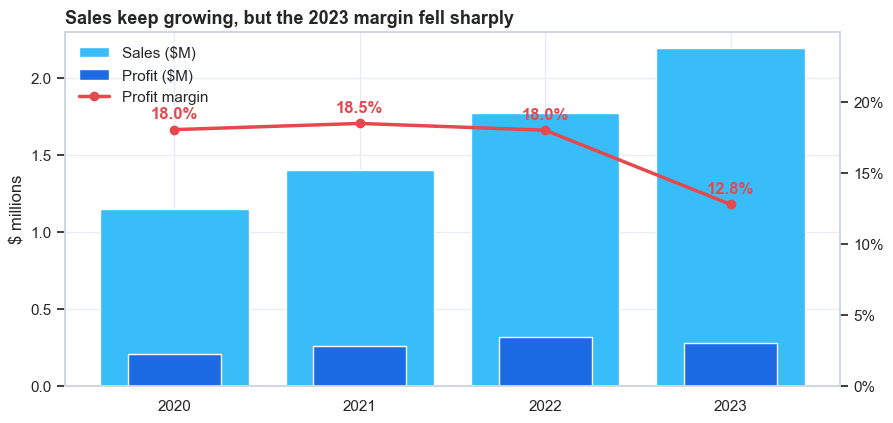

In [3]:
kpis = yearly_kpis(sales)
display(kpis[["sales", "profit", "margin", "orders", "customers", "new_customers", "aov", "avg_discount", "deep_discount_share"]])

fig, ax = plt.subplots(figsize=(10, 4.6))
x = kpis.index.astype(str)
ax.bar(x, kpis["sales"] / 1e6, color=SKY, label="Sales ($M)")
ax.bar(x, kpis["profit"] / 1e6, color=BLUE, width=0.5, label="Profit ($M)")
ax.set_ylabel("$ millions")
ax2 = ax.twinx()
ax2.plot(x, kpis["margin"], color=RED, marker="o", linewidth=2.5, label="Profit margin")
percent_axis(ax2)
ax2.set_ylim(0, kpis["margin"].max() * 1.35)
ax2.grid(False)
for xi, m in zip(x, kpis["margin"]):
    ax2.annotate(f"{m:.1%}", (xi, m), textcoords="offset points", xytext=(0, 8), ha="center", color=RED, fontweight="bold")
ax.set_title("Sales keep growing, but the 2023 margin fell sharply")
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(handles, ["Sales ($M)", "Profit ($M)", "Profit margin"], loc="upper left", frameon=False)
save(fig, FIGURES, "01_yearly_sales_profit_margin")
plt.show()

- Sales grew every year, from **$1.15M (2020) to $2.19M (2023)**, driven by more customers rather than larger baskets (AOV stays at about $248–257).
- **2023 broke the pattern:** sales +23.8% vs 2022, but profit −12.2% ($318.7K → $279.9K) and the margin fell 5.2 pp to 12.8%. At 2023 volumes that gap is worth about **$115K of profit**.
- The share of deeply discounted lines did not change (21–22% every year), so section 3.1 checks other explanations.

### 3.1 What caused the 2023 margin drop?
Three candidate explanations are tested: more discounting, a shift towards low-margin categories, or lower unit margins
across the board.

Profit margin by discount band and year


discount_band,No discount,1–20%,21–40%,>40%
year,,,,
2020,0.337,0.160,-0.046,-0.261
2021,0.335,0.162,-0.072,-0.245
2022,0.334,0.175,-0.082,-0.267
2023,0.281,0.115,-0.104,-0.292


Category margin (2022 vs 2023) and share of sales


,2022 margin,2023 margin,2022 sales share,2023 sales share
Category,,,,
Body care,0.178,0.136,0.516,0.511
Face care,0.225,0.143,0.058,0.052
Hair care,0.187,0.118,0.145,0.141
Home and Accessories,0.151,0.097,0.155,0.161
Make up,0.197,0.139,0.126,0.135


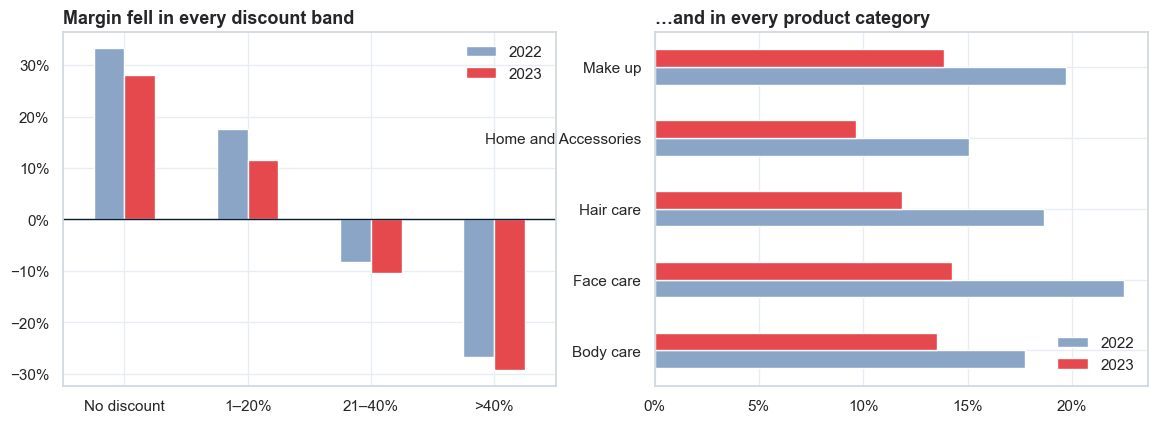

In [4]:
products = load_products(DATA_DIR)
enriched = sales.merge(products[["ProductCode", "Category"]], on="ProductCode", how="left")
enriched["discount_band"] = pd.cut(enriched["Discount"], bins=DISCOUNT_BINS, labels=DISCOUNT_LABELS)

band_margin = margin_by_year(enriched, "discount_band")
category_margin = margin_by_year(enriched, "Category").loc[[2022, 2023]].T
category_mix = enriched[enriched["OrderDate"].dt.year.isin([2022, 2023])].pivot_table(
    index="Category", columns=enriched["OrderDate"].dt.year, values="Sales", aggfunc="sum", observed=False)
category_mix = category_mix / category_mix.sum()

print("Profit margin by discount band and year")
display(band_margin)
print("Category margin (2022 vs 2023) and share of sales")
display(category_margin.join(category_mix, lsuffix=" margin", rsuffix=" sales share"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
band_margin.loc[[2022, 2023]].T.plot(kind="bar", color=[GREY, RED], ax=axes[0], rot=0)
axes[0].set_title("Margin fell in every discount band")
percent_axis(axes[0])
axes[0].set_xlabel("")
category_margin.plot(kind="barh", color=[GREY, RED], ax=axes[1])
axes[1].set_title("…and in every product category")
percent_axis(axes[1], axis="x")
axes[1].set_ylabel("")
for ax in axes:
    ax.legend(ax.containers, ["2022", "2023"], frameon=False)
axes[0].axhline(0, color=NAVY, linewidth=1)
save(fig, FIGURES, "01b_margin_drop_diagnosis")
plt.show()

- **Not discounting:** the margin fell inside every discount band, including undiscounted lines (33.4% → 28.1%), while the discount mix stayed the same.
- **Not product mix:** every category lost 4–8 pp of margin (Face care 22.5% → 14.3%), while category shares of sales moved by less than 1 pp.
- **Conclusion:** unit economics changed across the whole catalogue in 2023, through higher costs, lower list prices or both. The dataset has no cost or list-price fields, so the exact cause needs data from finance or procurement. This is the first question to take to management.

## 4. Build monthly cohorts
Each customer belongs to the month of their **first purchase**. Several lines of one order on the same day count as a single
purchase event. The *cohort index* is the number of months since the first purchase (0 = acquisition month).

25,719 purchase events · 17,415 customers · 48 monthly cohorts


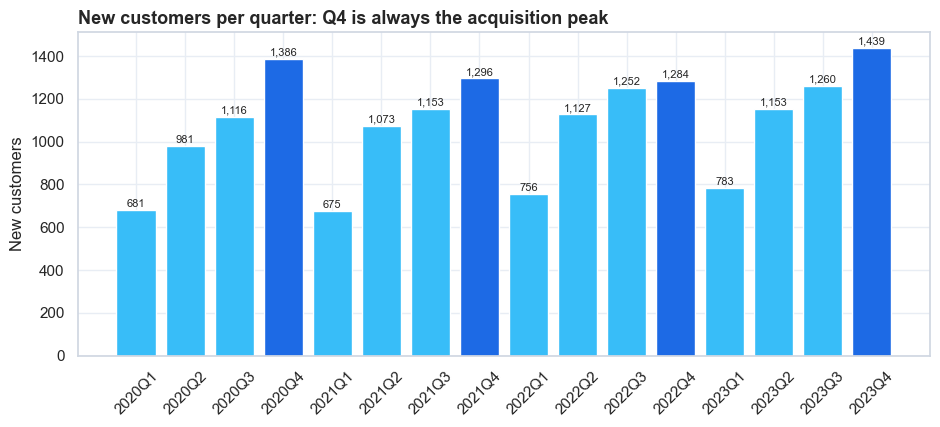

In [5]:
events = purchase_events(sales)
monthly = add_cohort_columns(events, freq="M")
monthly_counts = cohort_counts(monthly)
monthly_retention = retention_matrix(monthly_counts)

quarterly = add_cohort_columns(events, freq="Q")
quarterly_counts = cohort_counts(quarterly)
quarterly_retention = retention_matrix(quarterly_counts)

print(f"{len(events):,} purchase events · {events['CustomerID'].nunique():,} customers · {len(monthly_counts)} monthly cohorts")

sizes = quarterly_counts[0]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(sizes.index.astype(str), sizes.values, color=[BLUE if q.quarter == 4 else SKY for q in sizes.index])
ax.set_title("New customers per quarter: Q4 is always the acquisition peak")
ax.set_ylabel("New customers")
ax.tick_params(axis="x", rotation=45)
for i, v in enumerate(sizes.values):
    ax.text(i, v + 15, f"{int(v):,}", ha="center", fontsize=8)
save(fig, FIGURES, "02_new_customers_per_quarter")
plt.show()

Acquisition is healthy and seasonal: **Q4 is the largest cohort every year** (peak 1,439 new customers in 2023Q4) and Q1 the smallest (675–783). New customers per year grew from 4,164 to 4,635.

## 5. Monthly retention: the first-month cliff

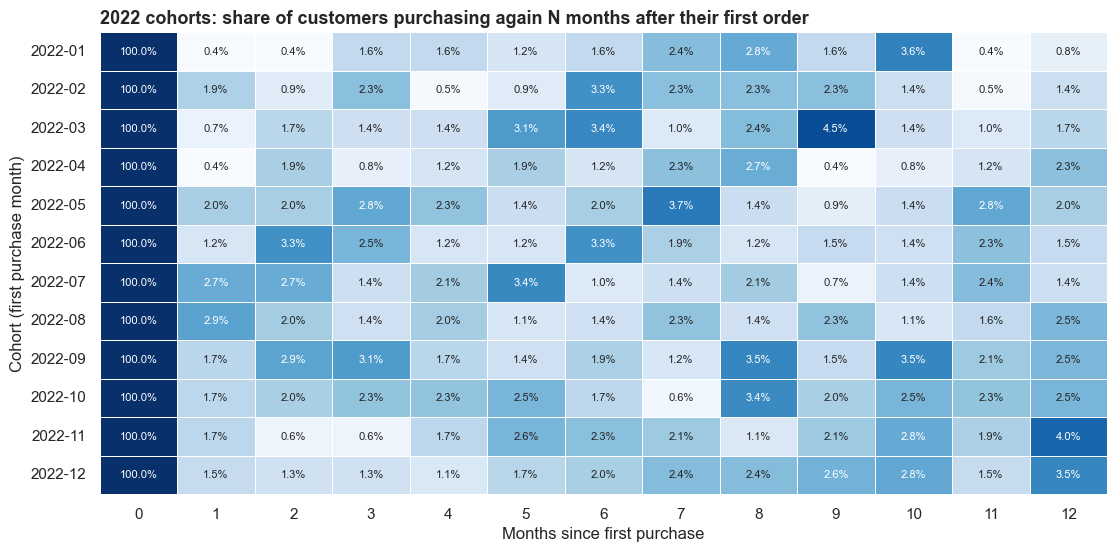

Size-weighted retention, all 48 cohorts: {'M1': '1.6%', 'M3': '1.8%', 'M6': '1.8%', 'M12': '2.2%', 'M24': '2.4%'}


In [6]:
cohorts_2022 = monthly_retention.loc["2022-01":"2022-12", 0:12]

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(cohorts_2022, annot=True, fmt=".1%", cmap="Blues", vmax=0.05, cbar=False,
            linewidths=0.5, linecolor="white", annot_kws={"size": 8}, ax=ax)
ax.set_title("2022 cohorts: share of customers purchasing again N months after their first order")
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort (first purchase month)")
save(fig, FIGURES, "03_monthly_retention_heatmap_2022")
plt.show()

curve = pooled_retention(monthly_counts)
print("Size-weighted retention, all 48 cohorts:", {f"M{k}": f"{curve[k]:.1%}" for k in (1, 3, 6, 12, 24)})

- After the acquisition month, only **0.4%–2.9%** of a 2022 cohort purchases in any single later month. Size-weighted across all cohorts, retention is **1.6% at month 1** and **2.4% at month 24**.
- The curve does **not decay** after month 1; it rises slightly. Customers do not churn gradually; most simply never return, and those who do come back on long, irregular cycles. Retention tactics should therefore target the **second purchase**, not monthly engagement.

## 6. Quarterly retention: smoothing the noise

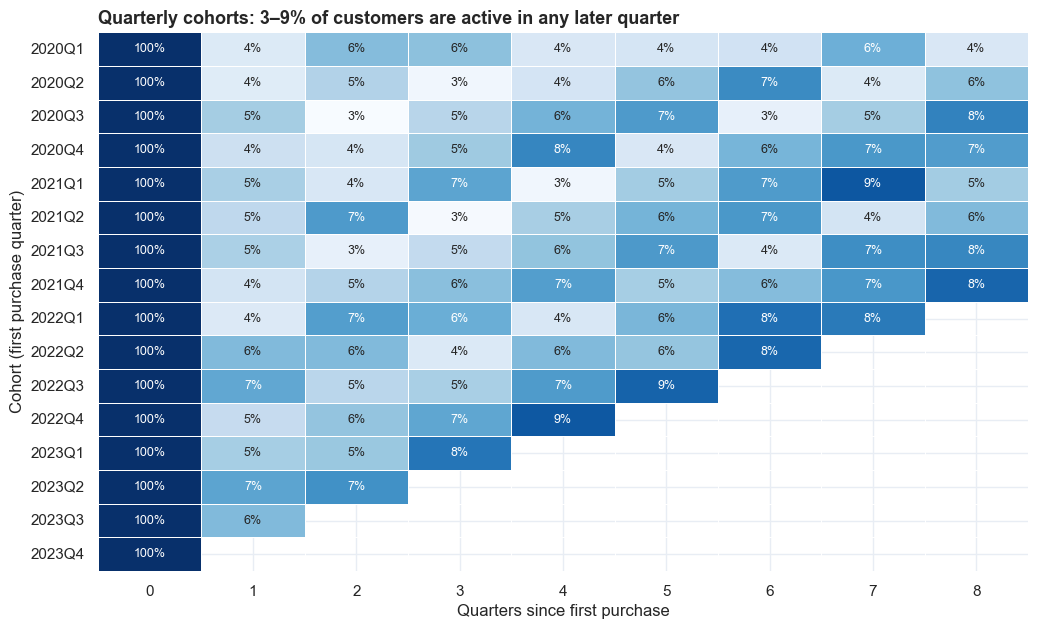

Quarterly retention range (Q1–Q8): 2.7% to 8.9%


In [7]:
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(quarterly_retention.loc[:, 0:8], annot=True, fmt=".0%", cmap="Blues", vmax=0.10, cbar=False,
            linewidths=0.5, linecolor="white", annot_kws={"size": 9}, ax=ax)
ax.set_title("Quarterly cohorts: 3–9% of customers are active in any later quarter")
ax.set_xlabel("Quarters since first purchase")
ax.set_ylabel("Cohort (first purchase quarter)")
save(fig, FIGURES, "04_quarterly_retention_heatmap")
plt.show()

later = quarterly_retention.loc[:, 1:8]
print(f"Quarterly retention range (Q1–Q8): {later.min().min():.1%} to {later.max().max():.1%}")

Grouping by quarter smooths the noise: within the first two years, **2.7%–8.9%** of a cohort is active in any later quarter, with no cohort clearly better or worse than the others. Retention is a structural feature of the business, not a problem of one campaign or season.

## 7. Why retention matters: the value of repeat customers

,customers,sales,profit,avg_profit_per_customer,customer_share,profit_share
type,,,,,,
One-time,11979,2978485,"464,209.496",38.752,0.688,0.436
Repeat (2+ orders),5436,3539189,"601,204.154",110.597,0.312,0.564


Median days to 2nd purchase: 364 · within 90 days: 14.5% · within 180 days: 27.7% · within 365 days: 50.1%


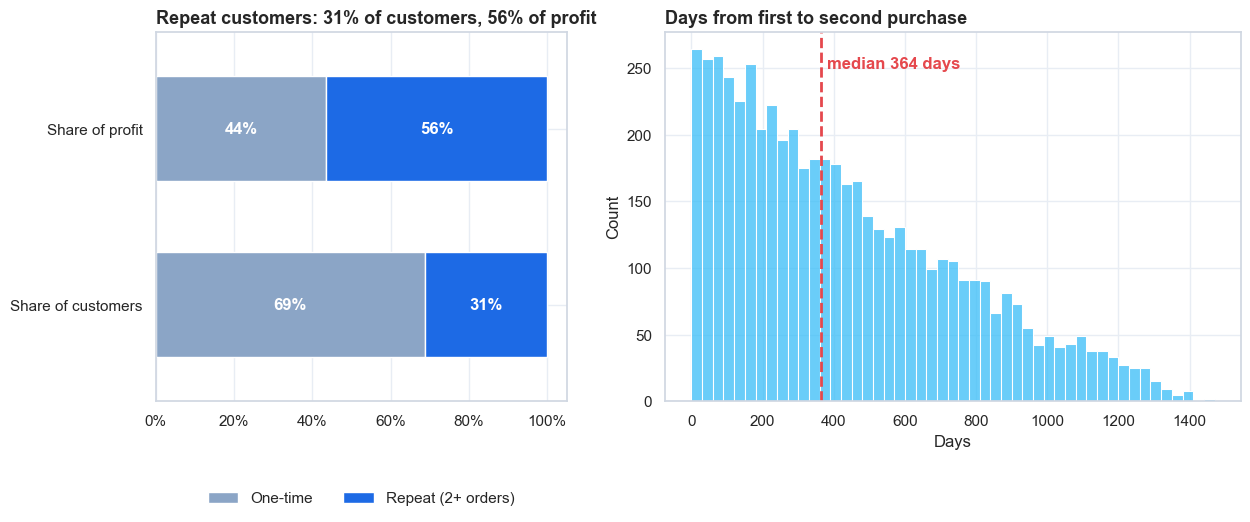

In [8]:
repeat = repeat_purchase_summary(sales)
display(repeat)

gaps = time_to_second_purchase(events)
print(f"Median days to 2nd purchase: {gaps.median():.0f} · within 90 days: {(gaps <= 90).mean():.1%} · "
      f"within 180 days: {(gaps <= 180).mean():.1%} · within 365 days: {(gaps <= 365).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
shares = repeat[["customer_share", "profit_share"]].T
shares.index = ["Share of customers", "Share of profit"]
shares.plot(kind="barh", stacked=True, color=[GREY, BLUE], ax=axes[0], width=0.6)
percent_axis(axes[0], axis="x")
axes[0].set_title("Repeat customers: 31% of customers, 56% of profit")
axes[0].legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=2)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt=lambda v: f"{v:.0%}", label_type="center", color="white", fontweight="bold")

sns.histplot(gaps, bins=range(0, 1500, 30), color=SKY, ax=axes[1])
axes[1].axvline(gaps.median(), color=RED, linestyle="--", linewidth=2)
axes[1].text(gaps.median() + 15, axes[1].get_ylim()[1] * 0.9, f"median {gaps.median():.0f} days", color=RED, fontweight="bold")
axes[1].set_title("Days from first to second purchase")
axes[1].set_xlabel("Days")
save(fig, FIGURES, "05_repeat_customer_value")
plt.show()

- **5,436 repeat customers (31%) generate $601K, or 56% of profit.** A repeat customer is worth **$110.6** in profit vs **$38.8** for a one-time buyer.
- Converting one more one-time buyer into a repeat buyer is worth about **$72** in profit. Moving 5% of the 11,979 one-time buyers (about 600 customers) would add about **$43K**.
- The second purchase comes late: **median 364 days**; 14.5% within 90 days, 27.7% within 180 days and 50.1% within a year. Purchases look **annual or replenishment-driven**, so reminders should be timed around months 10–12, with a lighter early nudge.

## 8. Segments: Consumer, Corporate and Self-Employed

,customers,sales,profit,repeat_rate,sales_share,profit_share,margin
Segment,,,,,,,
Consumer,8987,2146780,"365,377.602",0.315,0.329,0.343,0.170
Corporate,5221,3840707,"608,523.326",0.306,0.589,0.571,0.158
Self-Employed,3207,530187,"91,512.722",0.314,0.081,0.086,0.173


,Consumer,Corporate,Self-Employed
month,,,
1,1.7%,1.6%,1.6%
3,1.7%,1.9%,1.7%
6,2.1%,1.5%,1.6%
12,2.2%,2.4%,1.6%
24,2.2%,2.7%,2.5%


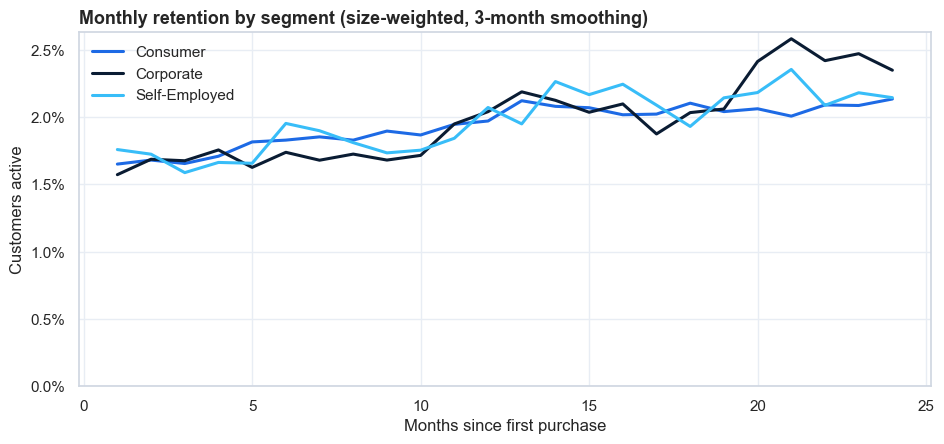

In [9]:
segments = segment_summary(sales)
display(segments)

segment_of = sales.groupby("CustomerID")["Segment"].first()
curves = {}
for name in segments.index:
    sub = monthly[monthly["CustomerID"].map(segment_of) == name]
    curves[name] = pooled_retention(cohort_counts(sub)).loc[1:24]
curves_table = pd.DataFrame(curves)
display(curves_table.loc[[1, 3, 6, 12, 24]].map("{:.1%}".format).rename_axis("month"))

fig, ax = plt.subplots(figsize=(11, 4.6))
for (name, curve), color in zip(curves.items(), [BLUE, NAVY, SKY]):
    ax.plot(curve.index, curve.rolling(3, center=True, min_periods=1).mean(), label=name, color=color, linewidth=2.2)
percent_axis(ax, decimals=1)
ax.set_ylim(0, None)
ax.set_title("Monthly retention by segment (size-weighted, 3-month smoothing)")
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Customers active")
ax.legend(frameon=False)
save(fig, FIGURES, "06_retention_by_segment")
plt.show()

- **Corporate** customers are 30% of the base but bring **59% of sales and 57% of profit**, at a slightly lower margin (15.8%) than Consumer (17.0%) and Self-Employed (17.3%).
- Loyalty is the same across segments: repeat rates are **30.6%–31.5%** and size-weighted monthly retention stays between **1.5% and 2.7%** for all three, with no consistent leader.
- Corporate accounts deserve account management because of their value, not because of different loyalty.

## 9. Profitability by customer income

,customers,sales,profit,profit_per_customer,customer_share,profit_share,margin
income_bracket,,,,,,,
<$50k,8139,3097998,"504,525.342",61.989,0.467,0.474,0.163
$50k–80k,6437,2414607,"399,964.624",62.135,0.370,0.375,0.166
$80k–110k,1766,633840,"102,622.730",58.110,0.101,0.096,0.162
>$110k,1073,371229,"58,300.954",54.335,0.062,0.055,0.157


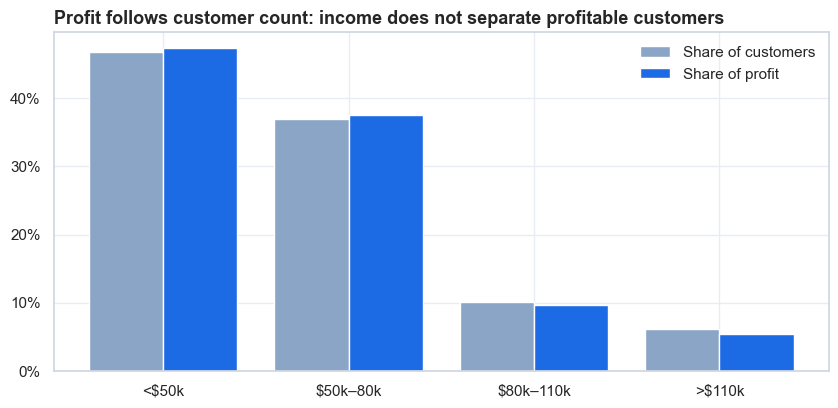

In [10]:
income = income_profitability(sales, customers)
display(income)

fig, ax = plt.subplots(figsize=(10, 4.4))
pos = range(len(income))
ax.bar([p - 0.2 for p in pos], income["customer_share"], width=0.4, color=GREY, label="Share of customers")
ax.bar([p + 0.2 for p in pos], income["profit_share"], width=0.4, color=BLUE, label="Share of profit")
ax.set_xticks(list(pos), income.index.astype(str))
percent_axis(ax)
ax.set_title("Profit follows customer count: income does not separate profitable customers")
ax.legend(frameon=False)
save(fig, FIGURES, "07_income_profitability")
plt.show()

Each income bracket's share of profit is within one percentage point of its share of customers, and profit per customer only ranges from **$54 to $62**; margins sit at 15.7%–16.6%. Income does **not** identify profitable customers here. Behavioural variables (recency, frequency, monetary value, discount sensitivity) are better targeting inputs.

## 10. Discounts: where the profit leaks

,order_lines,sales,profit,loss_making_lines,line_share,margin
discount_band,,,,,,
No discount,29009,3580519,"1,135,322.550",0,0.566,0.317
1–20%,10953,1460289,"218,650.098",2706,0.214,0.150
21–40%,4367,584094,"-47,481.730",2243,0.085,-0.081
>40%,6961,892772,"-241,077.268",6092,0.136,-0.270


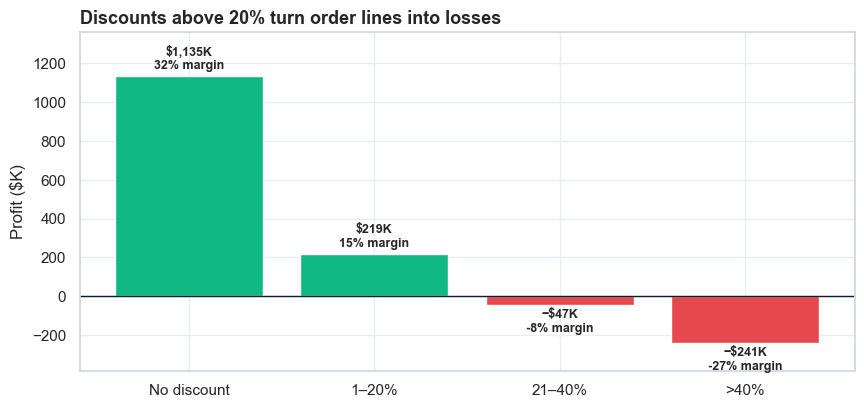

In [11]:
discounts = discount_profitability(sales)
display(discounts)

fig, ax = plt.subplots(figsize=(10, 4.4))
colors = [GREEN if p > 0 else RED for p in discounts["profit"]]
ax.bar(discounts.index.astype(str), discounts["profit"] / 1e3, color=colors)
for i, (p, m) in enumerate(zip(discounts["profit"], discounts["margin"])):
    label = f"{'−' if p < 0 else ''}${abs(p)/1e3:,.0f}K\n{m:.0%} margin"
    ax.text(i, p / 1e3 + (20 if p > 0 else -20), label, ha="center", va="bottom" if p > 0 else "top",
            fontsize=9, fontweight="bold")
ax.axhline(0, color=NAVY, linewidth=1)
ax.set_ylim(discounts["profit"].min() / 1e3 * 1.6, discounts["profit"].max() / 1e3 * 1.2)
ax.set_ylabel("Profit ($K)")
ax.set_title("Discounts above 20% turn order lines into losses")
save(fig, FIGURES, "08_discount_profit_leakage")
plt.show()

- Undiscounted lines (57% of lines) earn a **31.7%** margin; 1–20% discounts still earn 15.0%.
- Above 20% every band loses money: **21–40% → −8.1%** margin, **>40% → −27.0%** margin. Together these 11,328 lines lost **$288.6K**, and 74% of them were loss-making.
- A discount cap at 20% (or approval for deeper discounts) is the fastest profit lever available.

## 11. Export tables for the report

In [12]:
exports = {
    "data_quality_checks": quality,
    "yearly_kpis": kpis,
    "margin_by_discount_band": band_margin,
    "margin_by_category": category_margin,
    "monthly_retention": monthly_retention,
    "quarterly_retention": quarterly_retention,
    "repeat_vs_one_time": repeat,
    "segment_summary": segments,
    "income_profitability": income,
    "discount_profitability": discounts,
}
for name, table in exports.items():
    out = table.copy()
    out.index = out.index.astype(str)
    out.columns = out.columns.astype(str)
    out.to_csv(TABLES / f"{name}.csv")
print(f"Wrote {len(exports)} tables to {TABLES.relative_to(ROOT)} and figures to {FIGURES.relative_to(ROOT)}")

Wrote 10 tables to reports\tables and figures to reports\figures


## 12. Key findings
1. **2023 margin erosion is company-wide:** margin fell from 18.0% to 12.8% in every category and every discount band, worth about $115K of profit at 2023 sales.
2. **Repeat customers drive profit:** 31% of customers generate 56% of profit; each one is worth 2.9× a one-time buyer.
3. **Retention is low but stable:** about 1.6%–2.4% of a cohort is active in any later month, with no decay curve; most customers never return.
4. **Second purchases follow an annual rhythm:** median 364 days, and only 14.5% return within 90 days.
5. **Deep discounts lose money:** discounts above 20% lost $288.6K over four years.
6. **Corporate is the profit core:** 30% of customers, 57% of profit, with the same retention as other segments.
7. **Income does not predict profitability:** profit per customer is $54–62 across brackets.

## 13. Recommendations
| # | Action | Owner | Evidence | Expected impact |
|---|---|---|---|---|
| 1 | **Investigate the 2023 margin drop** with cost and list-price data before setting 2024 targets | Finance · Procurement | Margin −5.2 pp in every category and discount band | Recover up to about $115K a year |
| 2 | **Cap discounts at 20%**; require approval and a margin check above it | Commercial | Lines above 20% discount lost $288.6K | Up to about $72K a year if deep discounts are only brought to break-even |
| 3 | **Second-purchase programme** timed around months 10–12 (replenishment reminders, loyalty credit), plus an A/B-tested 60–90-day nudge | CRM · Marketing | Median 364 days to 2nd purchase; a repeat buyer is worth +$72 | +5% conversion of one-time buyers ≈ +$43K |
| 4 | **Corporate account management** (reorder cadence, volume pricing without deep discounts) | Sales | 30% of customers, 57% of profit | Protects the largest profit pool |
| 5 | **Replace income-based targeting** with RFM and discount-sensitivity segments | Marketing analytics | Profit per customer is flat across income brackets | Better targeting at no extra cost |

## 14. Limitations
- **Synthetic educational data:** patterns are realistic but not from a real company.
- **No cost or list-price fields:** the cause of the 2023 margin drop cannot be identified from this dataset alone.
- **Purchase-based retention:** a customer counts as retained only when they buy again; browsing and other engagement are not observed.
- **Right-censoring:** recent cohorts (2023) have fewer months of history, so long-horizon retention is based on older cohorts.
- **Descriptive, not causal:** impact estimates are simple sizing exercises; recommendations 2 and 3 should be validated with controlled tests.